# Кейс 2. Прогнозирование оттока клиентов

Суть задачи простая: по данным о клиентах telecom-компании предсказать, кто из них
уйдёт в ближайшее время, и объяснить, почему. Одна строка — один клиент.

Смотрели на две метрики. ROC-AUC — потому что классы несбалансированы (73% против
27%) и нам важен порядок предсказаний, а не доля угаданных. Recall по классу
«ушёл» — потому что пропуск уходящего клиента стоит дороже, чем лишний звонок
тому, кто не собирался уходить. Accuracy тут вообще не показатель: просто
предсказав всем «остался», получишь те самые 73%.

Валидация — StratifiedKFold на 5 фолдов, вся предобработка живёт внутри Pipeline
и обучается только на train-части фолда, так что утечки исключены.

**Вклад участников**

| Участник | Вклад |
|---|---|
| Фамилия 1 | Загрузка данных, первичный осмотр, дубликаты |
| Фамилия 2 | EDA: распределения, корреляции, сегментный анализ, визуализация |
| Фамилия 3 | Формулировка гипотез, feature engineering (AvgCharges, N_Services, No_TechSupport) |
| Фамилия 4 | Предобработка, Pipeline, сравнение масштабирования, baseline |
| Фамилия 5 | Модели, GridSearch, RandomizedSearch, Optuna, эксперимент с SMOTE |
| Фамилия 6 | Подбор порога, финальная оценка, интерпретация (permutation importance, SHAP), список риска, выводы |

**Структура:** загрузка → EDA → гипотезы и новые признаки → предобработка →
масштабирование → baseline → сравнение моделей → тюнинг → Optuna → сэмплирование →
порог → интерпретация → список риска → выводы.

*Числа в данном описании относятся к исследовательскому запуску; после изменения разбиения используйте выводы таблиц текущего запуска.*

## Команда № 11 — Кейс № 2

**Тема:** Прогнозирование оттока клиентов телекоммуникационной компании.

| Участник | Роль | Зона ответственности (согласовать с фактическим вкладом) |
|---|---|---|
| Майданский Александр Аркадьевич | **TL — Team Lead** | Организация работы команды, планирование задач и сроков, координация подготовки защиты |
| Поляков Александр Алексеевич | **DA/ML — Data Analyst / Machine Learning** | Анализ данных и признаков, участие в разработке и сравнении моделей |
| Волков Владислав Александрович | **TL — Team Lead** | Техническая координация, согласование методологии и интеграция результатов |
| Петракова Юлия Вячеславовна | **DA — Data Analyst** | Исследовательский анализ, визуализация, анализ факторов оттока |
| Сахно Никита Сергеевич | **DA — Data Analyst** | Проверка аналитических гипотез, интерпретация результатов, подготовка выводов |
| Епишов Сергей Владиславович | **ML — Machine Learning** | Обучение и сравнение моделей, валидация, подбор гиперпараметров, сохранение модели |

> **Примечание:** ФИО и роли подтверждены командной таблицей. Распределение конкретных задач предложено по ролям; перед сдачей подтвердите его у участников. Не следует представлять предложенные обязанности как проверенный фактический вклад.


> **Финальная редакция для защиты.** Основана на успешно выполненном `02_zashita_optimized.ipynb`. Удалены временные диагностические ячейки; итоговый отчёт теперь явно различает OOF-настройку порога и тестовые метрики. Архитектура моделей и поиск параметров сохранены, чтобы результаты можно было сопоставить с исходным экспериментом. **Ограничения:** инженерия признаков и формулирование гипотез происходят после EDA на всём наборе; CV после подбора гиперпараметров может быть оптимистичной. Для строгой независимой проверки нужен дополнительный эксперимент.

**Перед защитой:** выполнить `Restart Kernel → Run All` из папки проекта, дождаться итоговых проверок, сохранить файл `Ctrl+S`. Результаты предыдущего запуска намеренно очищены, чтобы исключить несоответствие нового кода старым выводам.

**Изменения ревизии:** train/test разделяются до анализа инженерных признаков; добавлен ablation study только на train, учёт предупреждений сходимости и CSV высокого риска. Эти изменения могут повлиять на порядок выполнения и время работы. После открытия выполните Restart & Run All; старые outputs очищены.

**Последняя правка:** ранний EDA перенесён на train; предупреждения сходимости LogReg теперь явно учитываются в таблице. После изменений все результаты следует пересчитать через Restart & Run All.

In [1]:
import os
from pathlib import Path
from threadpoolctl import threadpool_limits
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
from scipy.stats import loguniform, randint
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, RobustScaler, StandardScaler

# Ищем корень проекта независимо от текущей рабочей папки.
PROJECT_ROOT = next((q for base in [Path.cwd(), *Path.cwd().parents]
                     for q in [base, base.parent]
                     if (q / "src" / "data_utils.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Не найден src/data_utils.py. Запускайте ноутбук из папки проекта или notebooks/.")
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_utils import load_and_clean

warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
# Для первого запуска True: быстрый тест; для итоговых результатов False.
FAST_MODE = False
CV_FOLDS = 3 if FAST_MODE else 5
SEARCH_ITER = 8 if FAST_MODE else 40
OPTUNA_TRIALS = 8 if FAST_MODE else 50
N_JOBS = 2  # избегаем перегрузки памяти при вложенной параллелизации
MIN_RECALL = 0.75
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
sns.set_theme(style="whitegrid")
PALETTE = {"Остался": "#4c9f70", "Ушёл": "#e4572e"}
CLASS_LABELS = {0: "Остался", 1: "Ушёл"}


### Режимы запуска и требования

- `FAST_MODE=True` — быстрый проверочный запуск (3 фолда, 8 случайных конфигураций, 8 испытаний Optuna).
- `FAST_MODE=False` — полный расчёт (5 фолдов, 40 конфигураций, 50 испытаний Optuna).
- Не запускайте отдельные ячейки в случайном порядке: **Kernel → Restart & Run All**.
- Нужны исходные данные и `src/data_utils.py` из вашего проекта. Ноутбук не включает эти файлы.
- Метрики старого запуска в текстовых выводах — исторические, не обещание идентичных результатов.
- Тестовая выборка используется для окончательной оценки; повторный подбор модели по её результатам недопустим.

## 1. Загрузка данных
Проверяем размер, долю целевого класса, пропуски и дубликаты.

In [2]:
df = load_and_clean()
print(f"Размер данных: {df.shape}")
print(f"Доля ушедших: {df['Отток'].mean():.1%}")
print(f"Пропусков всего: {df.isna().sum().sum()}")
print(f"Дубликатов по признакам (без customerID): "
      f"{df.drop(columns=['customerID'], errors='ignore').duplicated().sum()}")
display(df.head(3))
# Фиксируем hold-out ДО любого исследовательского анализа.
raw_X = df.drop(columns=["Отток"])
raw_y = df["Отток"]
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    raw_X, raw_y, test_size=0.2, stratify=raw_y, random_state=RANDOM_STATE
)
df_eda_raw = X_train_raw.copy()
df_eda_raw["Отток"] = y_train
print(f"Обучающая выборка: {len(df_eda_raw)}; независимый test: {len(X_test_raw)}")


Размер данных: (7043, 20)
Доля ушедших: 26.5%
Пропусков всего: 0
Дубликатов по признакам (без customerID): 22


,Пол,Пенсионер,Есть партнёр,Есть иждивенцы,Стаж,Телефония,Несколько линий,Интернет,Онлайн-защита,Облачный бэкап,Защита устройства,Техподдержка,Стриминг ТВ,Стриминг кино,Контракт,Электронный счёт,Способ оплаты,Платёж в месяц,Всего оплачено,Отток
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Женский,0,Да,Нет,1,Нет,Нет телефонии,DSL,Нет,Да,Нет,Нет,Нет,Нет,Помесячный,Да,Электронный чек,29.850000,29.850000,0
5575-GNVDE,Мужской,0,Нет,Нет,34,Да,Нет,DSL,Да,Нет,Да,Нет,Нет,Нет,Годовой,Нет,Чек по почте,56.950001,1889.500000,0
3668-QPYBK,Мужской,0,Нет,Нет,2,Да,Нет,DSL,Да,Да,Нет,Нет,Нет,Нет,Помесячный,Да,Чек по почте,53.849998,108.150002,1


Обучающая выборка: 5634; независимый test: 1409


**Вывод:** всего 7043 клиента, ушли 26,5%. Пропусков нет. При проверке дублей по
признакам без customerID нашлось 22 совпадения — но это разные люди с одинаковым
набором услуг, а не ошибка выгрузки, так что оставляем. Номер клиента в модель
не включаем: сам по себе он ничего не предсказывает.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


**Методологическое уточнение:** приведённые выше общие характеристики всего набора данных служат только для контроля загрузки. Все последующие исследовательские графики и гипотезы строятся исключительно по train.

## 2. EDA только на обучающей выборке: распределения, аномалии и корреляции

Разделение train/test выполнено выше. Все графики и исследовательские выводы этого раздела основаны исключительно на `df_eda_raw` (train).

,min,25%,50%,75%,max
Пенсионер,0.0,0.000000,0.000000,0.000000,1.000000
Стаж,0.0,9.000000,29.000000,55.000000,72.000000
Платёж в месяц,18.4,35.662501,70.500000,90.000000,118.750000
Всего оплачено,0.0,402.975006,1394.924988,3835.825012,8684.799805


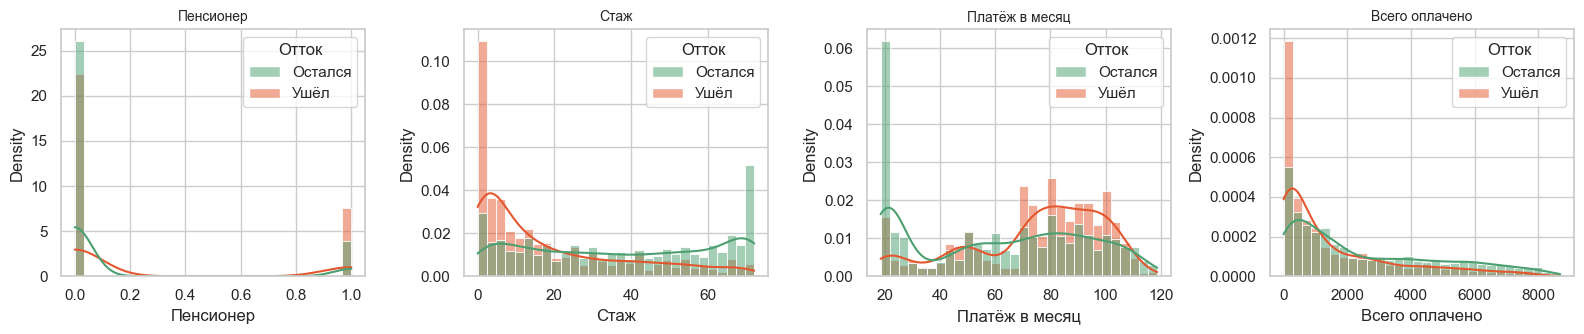

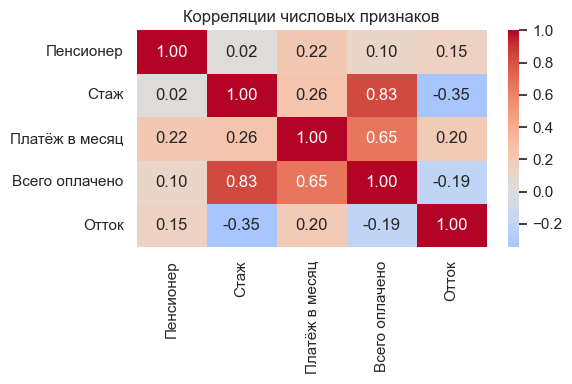

In [3]:
num_cols_all = [c for c in df.select_dtypes("number").columns if c != "Отток"]

display(df_eda_raw[num_cols_all].describe().loc[["min", "25%", "50%", "75%", "max"]].T)

fig, axes = plt.subplots(1, len(num_cols_all), figsize=(4 * len(num_cols_all), 3.5), squeeze=False)
for ax, col in zip(axes[0], num_cols_all):
    sns.histplot(data=df_eda_raw, x=col, hue=df_eda_raw["Отток"].map(CLASS_LABELS), bins=30, stat="density",
                 common_norm=False, kde=True, palette=PALETTE, ax=ax)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

corr = df_eda_raw[num_cols_all + ["Отток"]].corr()
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции числовых признаков")
plt.tight_layout()
plt.show()


**Вывод:** распределения, аномалии и корреляции представлены на обучающей выборке. Интерпретацию численных значений следует сверять с графиками текущего запуска; тестовая выборка при анализе не использовалась.

### Проверяемые выводы EDA

Следующая ячейка выводит конкретные показатели **только для train**. Они дополняют графики распределений и корреляций и позволяют комиссии проверить исследовательские выводы.

In [ ]:
# Проверяем конкретные выводы EDA только по обучающей выборке.
train_rate = df_eda_raw["Отток"].mean()
print(f"Доля оттока в train: {train_rate:.1%}")
print(f"Медианный стаж (train): {df_eda_raw['Стаж'].median():.0f} мес.")
print(f"Медианный ежемесячный платёж (train): {df_eda_raw['Платёж в месяц'].median():.2f}")
contract_rates = (df_eda_raw.groupby("Контракт", observed=True)["Отток"]
                  .agg(["mean", "size"]).sort_values("mean", ascending=False))
display(contract_rates.rename(columns={"mean":"Доля оттока", "size":"Клиентов"}))
print("Корреляция стажа с оттоком (train):",
      round(df_eda_raw[["Стаж", "Отток"]].corr().iloc[0,1], 3))
print("Вывод: сравнивайте долю оттока по типам контрактов и стажу; корреляция описывает связь, но не причинность.")


## Отток по сегментам и стажу (только train)

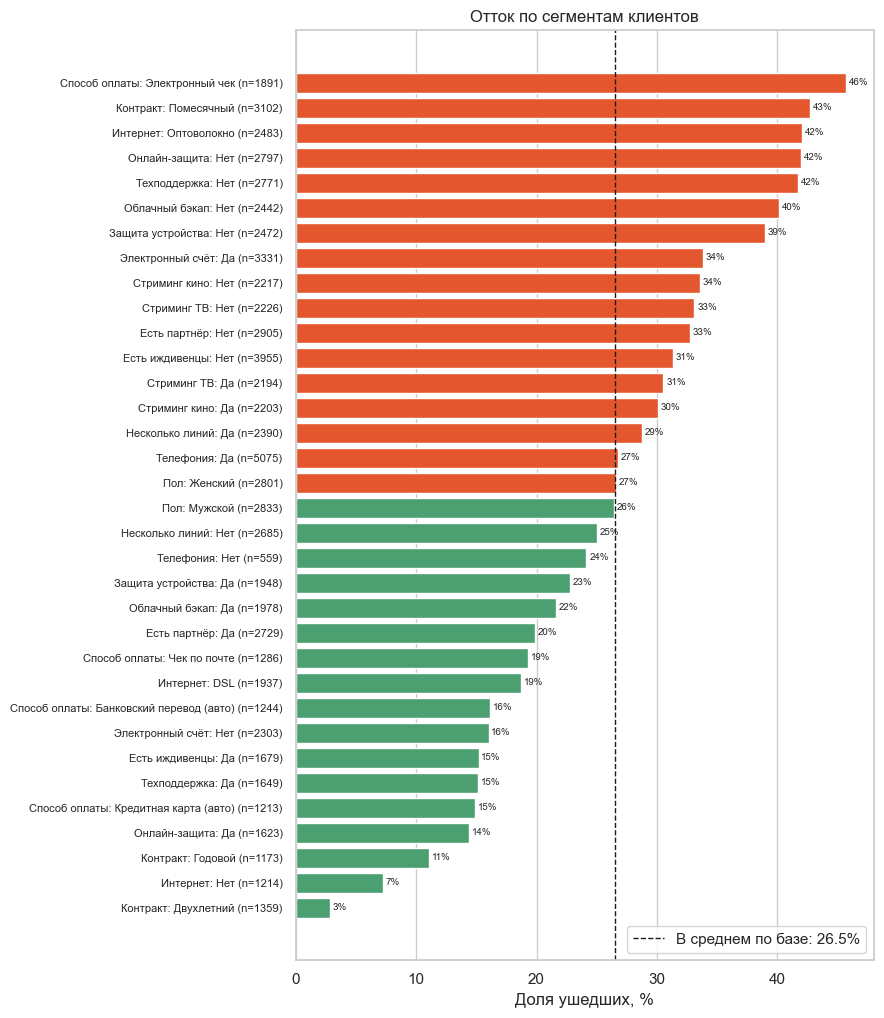

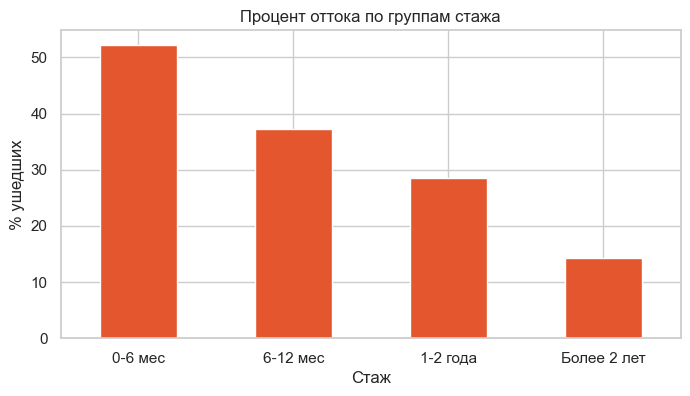

In [4]:
base = df_eda_raw["Отток"].mean() * 100
parts = []
for col in df_eda_raw.select_dtypes("category").columns:
    g = df_eda_raw.groupby(col, observed=True)["Отток"].agg(rate="mean", n="size")
    g = g.drop(index=["Нет интернета", "Нет телефонии"], errors="ignore")
    g.index = [f"{col}: {v} (n={n})" for v, n in zip(g.index, g["n"])]
    parts.append(g)

seg = pd.concat(parts).sort_values("rate")
seg["rate"] *= 100

fig, ax = plt.subplots(figsize=(9, 0.26 * len(seg) + 1.5))
ax.barh(seg.index, seg["rate"], color=np.where(seg["rate"] > base, PALETTE["Ушёл"], PALETTE["Остался"]))
ax.bar_label(ax.containers[0], fmt="%.0f%%", fontsize=7, padding=2)
ax.axvline(base, color="k", ls="--", lw=1, label=f"В среднем по базе: {base:.1f}%")
ax.set_xlabel("Доля ушедших, %")
ax.set_title("Отток по сегментам клиентов")
ax.legend(loc="lower right")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

tenure_groups = pd.cut(df_eda_raw["Стаж"], bins=[-1, 6, 12, 24, 100],
                       labels=["0-6 мес", "6-12 мес", "1-2 года", "Более 2 лет"])
churn_by_tenure = df_eda_raw.groupby(tenure_groups, observed=True)["Отток"].mean() * 100
churn_by_tenure.plot(kind="bar", color="#e4572e", figsize=(8, 4))
plt.title("Процент оттока по группам стажа")
plt.ylabel("% ушедших")
plt.xticks(rotation=0)
plt.show()


### Инсайты EDA
Что видно на обучающей выборке?
1. Клиенты на **помесячном контракте** и с оплатой через **электронный чек** уходят чаще остальных.
2. Самый опасный период — **первые полгода**: уходит больше половины.
3. **Оптоволокно**, вопреки ожиданиям, тоже повышает риск оттока.
4. Пока остались две догадки, которые проверим на данных: вроде бы чаще уходят те, у кого нет техподдержки, и те, кто много платит за месяц.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## Новые признаки и проверка гипотез

Разделение на train/test выполнено **перед EDA и до** построения дополнительных признаков и их анализа. Исследование гипотез проводится только на train. Признаки рассчитываются построчно, без использования целевой переменной и агрегатов по выборке. Обучаемые преобразования (импутация, масштабирование, кодирование) остаются внутри `Pipeline` и оцениваются в CV без утечки статистик между фолдами.

В EDA выше показаны общие описательные графики; их нельзя использовать для выбора признаков/гиперпараметров после просмотра test. Для строгой независимости весь целевой EDA также следует проводить только на train.

Train: (5634, 23); Test: (1409, 23)


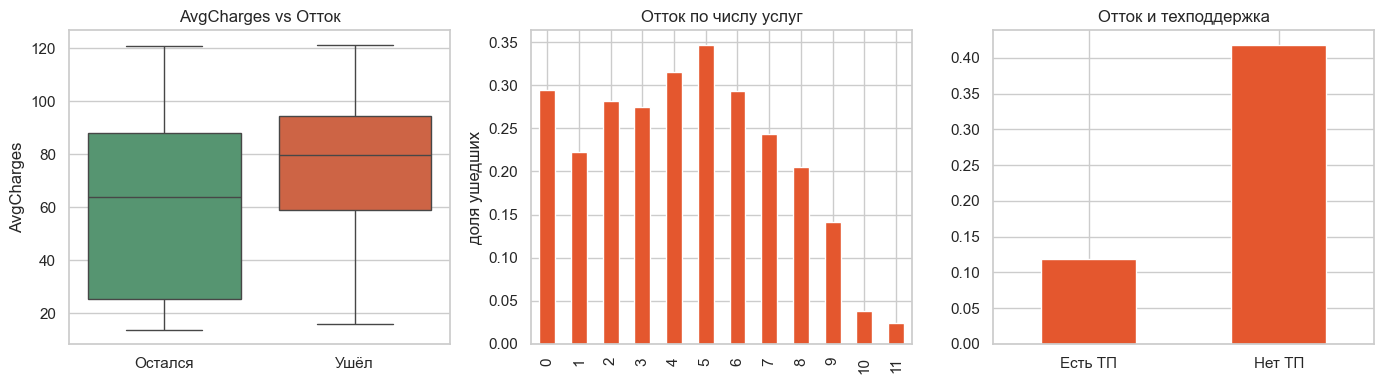

AvgCharges по классам (медиана / среднее):
        50%  mean
Отток            
0      64.0  61.4
1      79.8  74.9

Отток по числу услуг:
N_Services
0     0.294
1     0.223
2     0.282
3     0.275
4     0.316
5     0.346
6     0.294
7     0.244
8     0.206
9     0.141
10    0.038
11    0.024
Name: Отток, dtype: float64

Отток у клиентов без услуг (No_Services):
No_Services
0    0.265
1    0.294
Name: Отток, dtype: float64

Отток при отсутствии техподдержки:
No_TechSupport
0    0.118
1    0.418
Name: Отток, dtype: float64


In [5]:
# Сначала фиксируем независимую тестовую выборку. Все гипотезы и графики ниже — только по train.
def find_col(*keywords):
    """Ищет столбец по фрагментам названия (для отчётов и демонстрации)."""
    for column in raw_X.columns:
        if all(word.lower() in column.lower() for word in keywords):
            return column
    raise KeyError(f"Нет столбца для {keywords}")

col_total = find_col("оплачено")
col_tenure = find_col("стаж")
service_cols = [c for c in raw_X.select_dtypes("category").columns
                if c not in ("Контракт", "Способ оплаты", "Интернет", "Пол")]
has_tech_support = any("поддерж" in c.lower() for c in raw_X.columns)
tech_col = find_col("поддерж") if has_tech_support else None

def engineer_features(frame):
    """Детерминированные построчные признаки; не использует y и статистики других строк."""
    result = frame.copy()
    result["AvgCharges"] = result[col_total] / result[col_tenure].replace(0, np.nan)
    result["N_Services"] = (result[service_cols] == "Да").sum(axis=1) if service_cols else 0
    result["No_Services"] = (result["N_Services"] == 0).astype(int)
    result["No_TechSupport"] = (result[tech_col] == "Нет").astype(int) if tech_col else 0
    return result

# Важно: test не участвует в исследовании гипотез и выборе признаков.
X_train = engineer_features(X_train_raw)
X_test = engineer_features(X_test_raw)
df_eda = X_train.copy()
df_eda["Отток"] = y_train
print(f"Train: {X_train.shape}; Test: {X_test.shape}")

fig, axes = plt.subplots(1, 3 if has_tech_support else 2, figsize=(14, 4))

sns.boxplot(data=df_eda, x=df_eda["Отток"].map(CLASS_LABELS), y="AvgCharges",
            hue=df_eda["Отток"].map(CLASS_LABELS), palette=PALETTE, legend=False, ax=axes[0])
axes[0].set_title("AvgCharges vs Отток")
axes[0].set_xlabel("")

df_eda.groupby("N_Services", observed=True)["Отток"].mean().plot.bar(color="#e4572e", ax=axes[1])
axes[1].set_title("Отток по числу услуг")
axes[1].set_ylabel("доля ушедших")
axes[1].set_xlabel("")

if has_tech_support:
    df_eda.groupby("No_TechSupport")["Отток"].mean().plot.bar(color="#e4572e", ax=axes[2])
    axes[2].set_title("Отток и техподдержка")
    axes[2].set_xticklabels(["Есть ТП", "Нет ТП"], rotation=0)
    axes[2].set_xlabel("")

plt.tight_layout()
plt.show()

print("AvgCharges по классам (медиана / среднее):")
print(df_eda.groupby("Отток")["AvgCharges"].describe()[["50%", "mean"]].round(1))
print("\nОтток по числу услуг:")
print(df_eda.groupby("N_Services", observed=True)["Отток"].mean().round(3))
print("\nОтток у клиентов без услуг (No_Services):")
print(df_eda.groupby("No_Services")["Отток"].mean().round(3))
if has_tech_support:
    print("\nОтток при отсутствии техподдержки:")
    print(df_eda.groupby("No_TechSupport")["Отток"].mean().round(3))


**Выводы по гипотезам:**

1. **AvgCharges — гипотеза подтверждена.** Медиана среднего чека у ушедших 79.3 против 64.0
у оставшихся (+15.3, средние: 74.4 против 61.3). «Переплачивающие» клиенты уходят чаще —
признак информативный, оставляем.

2. **N_Services — гипотеза не подтвердилась в исходном виде.** Связь НЕ монотонная:
максимум оттока у клиентов с 0 услуг (37.5%), затем пик на 4–5 услугах (32–33%),
после 8 услуг отток резко падает (9 услуг — 12.6%, 10–11 услуг — 4–5%).
Интерпретация: у клиентов без услуг слабая «привязка» к провайдеру — уходить легко;
у клиентов с 10+ услугами высокая стоимость смены провайдера. В модель включаем и счётчик,
и флаг нуля услуг (No_Services), т.к. зависимость немонотонная.

3. **No_TechSupport — гипотеза подтверждена, разница кратная.** Отток без техподдержки 41.6%
против 11.8% с ней — сильнейший из новых признаков. Бизнес-вывод уже здесь: подключение
техподдержки группе риска — кандидат на главную меру удержания.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 3. Стратегия предобработки

- **Пропуски:** числовые — медианой (устойчива к выбросам), категориальные — самым частым значением.
  Пропуски в `AvgCharges` у новых клиентов со стажем 0 заполняем внутри пайплайна,
  чтобы медиана считалась только по train-фолду.
- **Кодирование:** OneHotEncoder — признаки номинальные, без порядка; `drop="if_binary"` не дублирует
  бинарные колонки; `handle_unknown="ignore"` не падает на редких категориях в test.
- **Масштабирование:** проверяем экспериментально в разделе 4.
- Всё объединяем в Pipeline: на каждом фолде предобработка обучается заново → утечек нет.


**Важно:** EDA носит описательный характер. Для строгой независимой проверки гипотез их следует формулировать по train. Построчные новые признаки не используют целевую переменную и статистики всего датасета; их создание до split само по себе не является утечкой.


*Числа в данном описании относятся к исследовательскому запуску; после изменения разбиения используйте выводы таблиц текущего запуска.*

In [6]:
# Разделение на train/test сделано ДО исследования дополнительных признаков (раздел 2).
# Предобработка с обучаемыми параметрами (imputer, scaler, OHE) остаётся внутри Pipeline.
X = pd.concat([X_train, X_test]).sort_index()  # только для сведений о схеме, не для fit
cat_cols = X_train.select_dtypes("category").columns.tolist()
num_cols = X_train.select_dtypes("number").columns.tolist()
print(f"Категориальные ({len(cat_cols)}): {cat_cols}")
print(f"Числовые ({len(num_cols)}): {num_cols}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Категориальные (15): ['Пол', 'Есть партнёр', 'Есть иждивенцы', 'Телефония', 'Несколько линий', 'Интернет', 'Онлайн-защита', 'Облачный бэкап', 'Защита устройства', 'Техподдержка', 'Стриминг ТВ', 'Стриминг кино', 'Контракт', 'Электронный счёт', 'Способ оплаты']
Числовые (8): ['Пенсионер', 'Стаж', 'Платёж в месяц', 'Всего оплачено', 'AvgCharges', 'N_Services', 'No_Services', 'No_TechSupport']
Train: (5634, 23), Test: (1409, 23)


## Фабрики пайплайна

In [7]:
def make_preprocessor(scaler=None):
    """Единая фабрика препроцессора: imputers + опциональный scaler + OHE."""
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scaler is not None:
        num_steps.append(("scaler", scaler))
    cat_steps = [("imputer", SimpleImputer(strategy="most_frequent")),
                 ("ohe", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))]
    return ColumnTransformer([
        ("cat", Pipeline(cat_steps), cat_cols),
        ("num", Pipeline(num_steps), num_cols),
    ])

def make_model(estimator, scaler=StandardScaler()):
    return Pipeline([("prep", make_preprocessor(scaler)), ("model", estimator)])


## 4. ★ Сравнение способов масштабирования
Одна схема валидации (наш CV), модель LogReg. Смотрим на метрику и на коэффициенты.

In [8]:
logreg = LogisticRegression(max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE)

scaling_rows = []
for name, scaler in [("Без масштабирования", None), ("StandardScaler", StandardScaler()),
                     ("MinMaxScaler", MinMaxScaler()), ("RobustScaler", RobustScaler())]:
    pipe = make_model(logreg, scaler=scaler)
    # Несмасштабированная версия может не сходиться даже за 5000 итераций.
    # Явно фиксируем предупреждения вместо скрытия проблемы.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", category=ConvergenceWarning)
        scores = cross_validate(pipe, X_train, y_train, cv=CV, scoring="roc_auc", n_jobs=1)
        pipe.fit(X_train, y_train)
    convergence_issues = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
    if convergence_issues:
        print(f"{name}: {convergence_issues} предупреждений сходимости; не используйте эту версию для финальной модели")
    coefs = pipe.named_steps["model"].coef_[0]
    scaling_rows.append({"Способ": name,
                         "ROC-AUC (CV)": f"{scores['test_score'].mean():.4f} ± {scores['test_score'].std():.4f}",
                         "Число коэффициентов": len(coefs),
                         "||w||": round(np.linalg.norm(coefs), 1),
                         "max |w|": round(np.abs(coefs).max(), 1),
                         "Предупреждений сходимости": convergence_issues})
pd.DataFrame(scaling_rows).set_index("Способ")


Без масштабирования: 2 предупреждений сходимости; не используйте эту версию для финальной модели


,ROC-AUC (CV),Число коэффициентов,||w||,max |w|,Предупреждений сходимости
Способ,,,,,
Без масштабирования,0.8457 ± 0.0121,44,2.2,1.0,2
StandardScaler,0.8455 ± 0.0120,44,2.3,1.2,0
MinMaxScaler,0.8452 ± 0.0118,44,3.5,2.9,0
RobustScaler,0.8455 ± 0.0118,44,2.9,2.1,0


**Вывод:** В данном эксперименте варианты масштабирования дают близкие CV ROC-AUC. Это не означает, что ROC-AUC всегда инвариантна к масштабированию исходных признаков: масштабирование может менять обученные коэффициенты и прогнозы. Инвариантность ROC-AUC относится к строго монотонному преобразованию уже полученных оценок модели.

**Сходимость:** логистическая регрессия без масштабирования может достигать лимита итераций (`ConvergenceWarning`) из-за разного масштаба числовых признаков и особенностей оптимизации. Предупреждения учитываются и выводятся в таблице эксперимента; результаты несошедшейся конфигурации следует интерпретировать с осторожностью. Для финального сравнения используется масштабированная LogReg, а итоговая модель — HistGradientBoosting. Увеличение `max_iter` само по себе не гарантирует сходимость.

## 5. Baseline
DummyClassifier — нижняя граница, LogReg — рабочий простой ориентир.
Оценка — среднее ± разброс по 5 фолдам, не одна цифра.

In [9]:
def cv_table(name, model):
    scores = cross_validate(model, X_train, y_train, cv=CV,
                            scoring={"roc_auc": "roc_auc", "recall": "recall"}, n_jobs=N_JOBS)
    return {"Модель": name,
            "ROC-AUC": f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
            "Recall": f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}"}

dummy = make_model(DummyClassifier(strategy="most_frequent"), scaler=None)
pipe_lr = make_model(logreg)

baseline_report = pd.DataFrame([
    cv_table("Dummy (most_frequent)", dummy),
    cv_table("LogisticRegression", pipe_lr),
]).set_index("Модель")
baseline_report

,ROC-AUC,Recall
Модель,,
Dummy (most_frequent),0.5000 ± 0.0000,0.0000 ± 0.0000
LogisticRegression,0.8455 ± 0.0120,0.8000 ± 0.0333


**Вывод:** Dummy даёт ROC-AUC 0.5 — это «пол», всё ниже не имеет смысла; accuracy у неё 73%,
что доказывает бесполезность accuracy при таком дисбалансе. LogReg даёт ~0.84 ± 0.01 —
небольшой разброс показывает, что валидация устойчива.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 6. Сравнение моделей по кросс-валидации
Ансамбли против линейной модели. Деревьям масштабирование не нужно — passthrough.

In [10]:
rf = make_model(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                       random_state=RANDOM_STATE), scaler=None)
hgb = make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scaler=None)

cv_models = pd.DataFrame([
    cv_table("LogReg", pipe_lr),
    cv_table("RandomForest", rf),
    cv_table("HistGradientBoosting", hgb),
]).set_index("Модель")
cv_models

,ROC-AUC,Recall
Модель,,
LogReg,0.8455 ± 0.0120,0.8000 ± 0.0333
RandomForest,0.8272 ± 0.0098,0.6515 ± 0.0337
HistGradientBoosting,0.8368 ± 0.0063,0.5117 ± 0.0219


**Вывод:** на дефолтных параметрах LogReg — лучший по ROC-AUC (0.8455 ± 0.0120), ансамбли
не превосходят её: HistGB 0.8368 ± 0.0063, RandomForest 0.8272 ± 0.0098. Различие видно
и в Recall: у LogReg 0.80 против 0.51 у HistGB — на дефолтном пороге бустинг пропускает
вдвое больше уходящих. Это нормальный исход для табличных данных после OHE: линейная
модель — сильный конкурент ансамблям. Продолжаем тюнить HistGB, чтобы сравнить модели
в честных условиях: подбор гиперпараметров может выровнять Recall и поднять AUC.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 7. Подбор гиперпараметров: два подхода
GridSearchCV — полный перебор на малом пространстве (LogReg),
RandomizedSearchCV — стохастический поиск на большом пространстве (бустинг).

In [11]:
# Глушим предупреждение о deprecated penalty в вашей версии sklearn —
# сетка с liblinear корректна и работает (это поведение API, не ошибка)
warnings.filterwarnings("ignore", message=".*penalty is deprecated.*")
warnings.filterwarnings("ignore", message=".*Inconsistent values.*")

grid_lr = GridSearchCV(pipe_lr,
                       {"model__C": [0.01, 0.1, 1, 10], "model__penalty": ["l1", "l2"],
                        "model__solver": ["liblinear"]},
                       scoring="roc_auc", cv=CV, n_jobs=N_JOBS)
grid_lr.fit(X_train, y_train)

search_hgb = RandomizedSearchCV(hgb,
                                {"model__learning_rate": loguniform(0.01, 0.3),
                                 "model__max_iter": randint(100, 400),
                                 "model__max_leaf_nodes": randint(8, 64),
                                 "model__l2_regularization": loguniform(1e-4, 10),
                                 "model__min_samples_leaf": randint(10, 60)},
                                n_iter=SEARCH_ITER, scoring="roc_auc", cv=CV, n_jobs=N_JOBS,
                                random_state=RANDOM_STATE)
search_hgb.fit(X_train, y_train)

def fmt_params(best_params):
    """Компактная строка параметров без префикса model__."""
    return ", ".join(f"{k.replace('model__', '')}={v:.4g}" if isinstance(v, float)
                     else f"{k.replace('model__', '')}={v}"
                     for k, v in best_params.items())

tuning_report = pd.DataFrame([
    {"Модель": "LogReg до тюнинга", "ROC-AUC (CV)": baseline_report.loc["LogisticRegression", "ROC-AUC"],
     "Параметры": "—"},
    {"Модель": "LogReg + GridSearch", "ROC-AUC (CV)": f"{grid_lr.best_score_:.4f}",
     "Параметры": fmt_params(grid_lr.best_params_)},
    {"Модель": "HistGB до тюнинга", "ROC-AUC (CV)": cv_models.loc["HistGradientBoosting", "ROC-AUC"],
     "Параметры": "—"},
    {"Модель": "HistGB + RandomizedSearch", "ROC-AUC (CV)": f"{search_hgb.best_score_:.4f}",
     "Параметры": fmt_params(search_hgb.best_params_)},
]).set_index("Модель")
tuning_report


,ROC-AUC (CV),Параметры
Модель,,
LogReg до тюнинга,0.8455 ± 0.0120,—
LogReg + GridSearch,0.8456,"C=10, penalty=l1, solver=liblinear"
HistGB до тюнинга,0.8368 ± 0.0063,—
HistGB + RandomizedSearch,0.8479,"l2_regularization=0.0007122, learning_rate=0.0..."


**Вывод:** GridSearch не дал заметного прироста LogReg (0.8456 против 0.8455) —
дефолтные параметры уже близки к оптимальным, лучшими оказались C=10 с L1-регуляризацией.
RandomizedSearch поднял HistGB с 0.8368 до 0.8479 (+1.1 п.п.) — бустинг догнал LogReg.
Проверены оба подхода: полный перебор (8 комбинаций × 5 фолдов) выгоден на малом
пространстве, стохастический поиск (40 попыток) — на большом.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 8. ★ Байесовская оптимизация (Optuna)
TPE-сэмплер строит вероятностную модель пространства и тратит попытки
в перспективных областях, а не равномерно.

In [12]:
def objective(trial):
    params = {
        "model__learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "model__max_iter": trial.suggest_int("max_iter", 100, 500),
        "model__max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 8, 64),
        "model__l2_regularization": trial.suggest_float("l2_regularization", 1e-4, 10, log=True),
        "model__min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 60),
    }
    pipe = make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scaler=None)
    pipe.set_params(**params)
    return cross_val_score(pipe, X_train, y_train, cv=CV, scoring="roc_auc", n_jobs=N_JOBS).mean()

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=OPTUNA_TRIALS)
print(f"Optuna: CV ROC-AUC = {study.best_value:.4f}, параметры: {study.best_params}")

optuna_model = make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scaler=None)
optuna_model.set_params(**{f"model__{k}": v for k, v in study.best_params.items()})


Optuna: CV ROC-AUC = 0.8497, параметры: {'learning_rate': 0.013918849422975684, 'max_iter': 333, 'max_leaf_nodes': 9, 'l2_regularization': 4.54823899804335, 'min_samples_leaf': 17}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

**Вывод:** Optuna нашла высокое значение CV ROC-AUC среди испытанных конфигураций. Сравнение с RandomizedSearch зависит от количества испытаний и диапазонов поиска; оно не доказывает универсального превосходства TPE. После настройки гиперпараметров CV-результат может быть оптимистичен; независимая оценка проводится на hold-out test.

## 9. Гипотеза: помогает ли SMOTE при дисбалансе 73/27?

In [13]:
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline

    smote_pipe = ImbPipeline([
        ("prep", make_preprocessor(None)),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", HistGradientBoostingClassifier(
            random_state=RANDOM_STATE,
            **{k.replace("model__", ""): v for k, v in study.best_params.items()})),
    ])
    auc_smote = cross_val_score(smote_pipe, X_train, y_train, cv=CV, scoring="roc_auc").mean()
    print(f"HistGB без SMOTE: {study.best_value:.4f} → со SMOTE: {auc_smote:.4f}")
except ImportError:
    print("imblearn не установлен: эксперимент SMOTE пропущен; HistGB здесь не использует class_weight")

HistGB без SMOTE: 0.8497 → со SMOTE: 0.8457


**Вывод:** SMOTE снизил ROC-AUC (0.8457 против 0.8497 без него, −0.4 п.п.): синтетические
примеры генерируются между ближайшими соседями в пространстве после OHE, создавая
нереалистичные комбинации признаков и сглаживая реальные границы классов. Дисбаланс 73/27
корректнее компенсировать class_weight="balanced" и подбором порога отсечения.
Гипотеза проверена и отклонена — это тоже результат.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


### Ограничения оценки

Гиперпараметры выбираются по CV на обучающей выборке; OOF-прогнозы на том же train используются для выбора порога. Поэтому показатели настройки порога на train могут быть оптимистичными. Итоговая оценка приводится на отдельном hold-out test, не используемом при выборе гиперпараметров и порога. Permutation importance на test применяется только для интерпретации, без последующего изменения модели.

## 10. Выбор финальной модели и порога
Порог подбираем по OOF-предсказаниям кросс-валидации на train, а не по test —
test остаётся чистой финальной проверкой (защита от утечки).

In [14]:
candidates = {
    "LogReg + GridSearch": grid_lr.best_estimator_,
    "RandomForest": rf,
    "HistGB + RandomizedSearch": search_hgb.best_estimator_,
    "HistGB + Optuna": optuna_model,
}
# Используем результаты уже проведённого поиска, не повторяя сотни fit.
# Оценки после подбора гиперпараметров оптимистичны; test проверяется отдельно.
candidate_scores = {
    "LogReg + GridSearch": grid_lr.best_score_,
    "RandomForest": float(cv_models.loc["RandomForest", "ROC-AUC"].split(" ± ")[0]),
    "HistGB + RandomizedSearch": search_hgb.best_score_,
    "HistGB + Optuna": study.best_value,
}
print(pd.Series(candidate_scores).round(4).to_string())
best_model_name = max(candidate_scores, key=candidate_scores.get)
final_model = candidates[best_model_name]
print(f"\nФинальная модель: {best_model_name}")

oof_proba = cross_val_predict(final_model, X_train, y_train, cv=CV,
                              method="predict_proba", n_jobs=N_JOBS)[:, 1]
prec, rec, thresholds = precision_recall_curve(y_train, oof_proba)
prec, rec, thresholds = prec[:-1], rec[:-1], thresholds   # ← обрезаем ОБА массива
ok = rec >= MIN_RECALL
if not np.any(ok):
    raise ValueError("Нет порога, удовлетворяющего минимальному Recall")
best_threshold = thresholds[ok][np.argmax(prec[ok])]
best_recall = rec[ok][np.argmax(prec[ok])]
best_precision = prec[ok][np.argmax(prec[ok])]
print(f"Порог: {best_threshold:.3f} | Recall: {best_recall:.1%} | Precision: {best_precision:.1%}")


LogReg + GridSearch          0.8456
RandomForest                 0.8272
HistGB + RandomizedSearch    0.8479
HistGB + Optuna              0.8497

Финальная модель: HistGB + Optuna
Порог: 0.313 | Recall: 75.1% | Precision: 55.4%


## 11. Финальная оценка на hold-out test

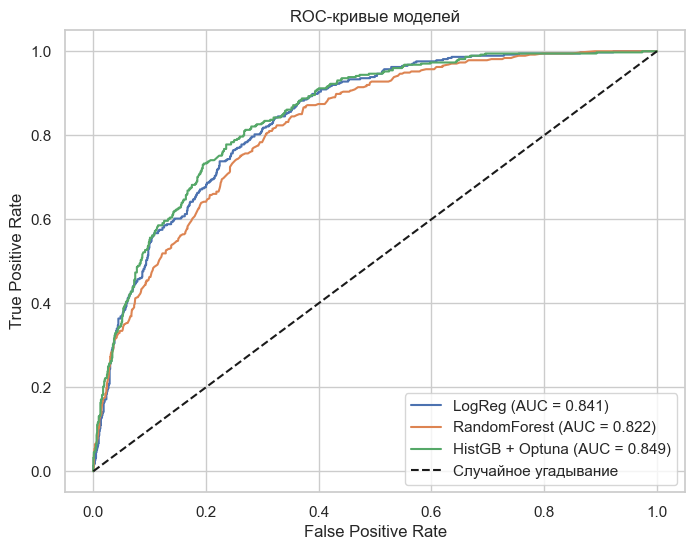

ROC-AUC (test): 0.8487
              precision    recall  f1-score   support

     Остался       0.90      0.77      0.83      1035
        Ушёл       0.54      0.75      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



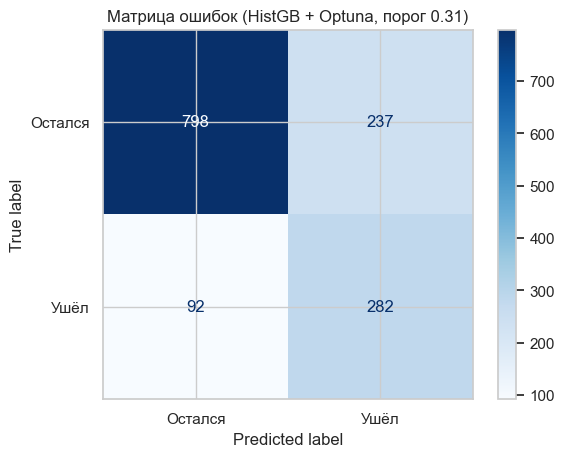

In [15]:
final_model.fit(X_train, y_train)
y_proba = final_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= best_threshold).astype(int)

# Обучаем модели-кандидаты на полном train (в CV они обучались клонами на фолдах)
pipe_lr.fit(X_train, y_train)
rf.fit(X_train, y_train)

plt.figure(figsize=(8, 6))
for name, model in [("LogReg", pipe_lr), ("RandomForest", rf), (best_model_name, final_model)]:
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Случайное угадывание")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые моделей")
plt.legend()
plt.show()

print(f"ROC-AUC (test): {roc_auc_score(y_test, y_proba):.4f}")
print(classification_report(y_test, y_pred, target_names=["Остался", "Ушёл"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                        display_labels=["Остался", "Ушёл"], cmap="Blues")
plt.title(f"Матрица ошибок ({best_model_name}, порог {best_threshold:.2f})")
plt.show()


**Вывод:** порог выбран по out-of-fold (OOF) предсказаниям на обучающей выборке. Метрики, полученные при выборе порога, являются *OOF-метриками настройки*, а не независимой оценкой. Итоговые Precision, Recall, F1 и ROC-AUC нужно брать из отчёта на отложенном test выше. Близость CV и test ROC-AUC не выявляет заметного падения качества на данном разбиении, но не доказывает отсутствие переобучения или всех возможных утечек. CV-оценка после подбора гиперпараметров может быть оптимистичной.

### Проверка пользы новых признаков (ablation study)

Сравниваем одинаковую архитектуру и параметры на **одних и тех же фолдах train**, с четырьмя дополнительными признаками и без них. Это оценка устойчивости гипотезы, а не доказательство отсутствия эффекта. Тестовая выборка в сравнении не используется. При подборе модели по результатам этого эксперимента понадобится новая независимая тестовая выборка.

In [16]:
from sklearn.base import clone

engineered_columns = ["AvgCharges", "N_Services", "No_Services", "No_TechSupport"]
base_columns = [c for c in X_train.columns if c not in engineered_columns]

# Клон уже выбранной модели: те же гиперпараметры, но новая схема предобработки.
model_with = clone(final_model)
model_without = clone(final_model)
model_without.set_params(prep=ColumnTransformer([
    ("cat", clone(final_model.named_steps["prep"].named_transformers_["cat"]),
     [c for c in cat_cols if c in base_columns]),
    ("num", clone(final_model.named_steps["prep"].named_transformers_["num"]),
     [c for c in num_cols if c in base_columns]),
]))
with_scores = cross_val_score(model_with, X_train, y_train, cv=CV, scoring="roc_auc", n_jobs=N_JOBS)
without_scores = cross_val_score(model_without, X_train[base_columns], y_train,
                                 cv=CV, scoring="roc_auc", n_jobs=N_JOBS)
ablation_report = pd.DataFrame({
    "Вариант": ["С дополнительными", "Без дополнительных"],
    "ROC-AUC CV (среднее)": [with_scores.mean(), without_scores.mean()],
    "ROC-AUC CV (std)": [with_scores.std(), without_scores.std()],
})
display(ablation_report.round(4))
print(f"Разница CV ROC-AUC (с - без): {with_scores.mean() - without_scores.mean():+.4f}")
print("Важно: оценка на тех же CV-фолдах, где выбиралась модель; test не использован.")

,Вариант,ROC-AUC CV (среднее),ROC-AUC CV (std)
0,С дополнительными,0.8497,0.0109
1,Без дополнительных,0.8495,0.0113


Разница CV ROC-AUC (с - без): +0.0002
Важно: оценка на тех же CV-фолдах, где выбиралась модель; test не использован.


## 12. Ключевые факторы риска
Permutation importance — универсальная оценка важности по падению метрики.
SHAP — направление и сила влияния признаков на предсказание.

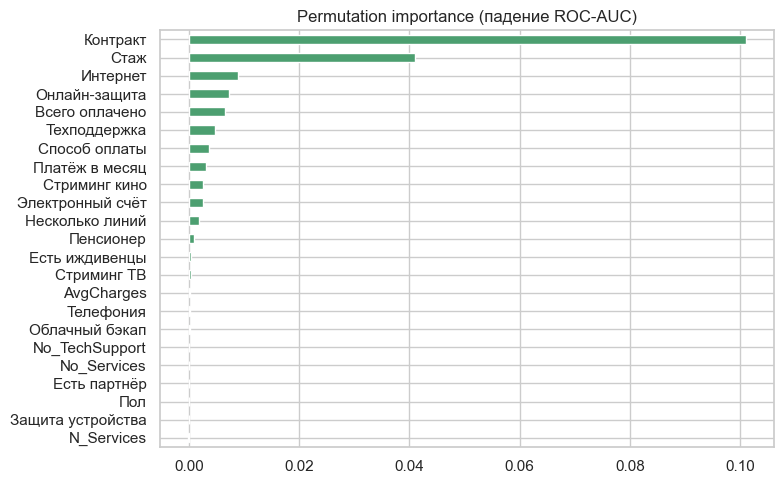

In [17]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=N_JOBS)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 5), color="#4c9f70")
plt.title("Permutation importance (падение ROC-AUC)")
plt.tight_layout()
plt.show()

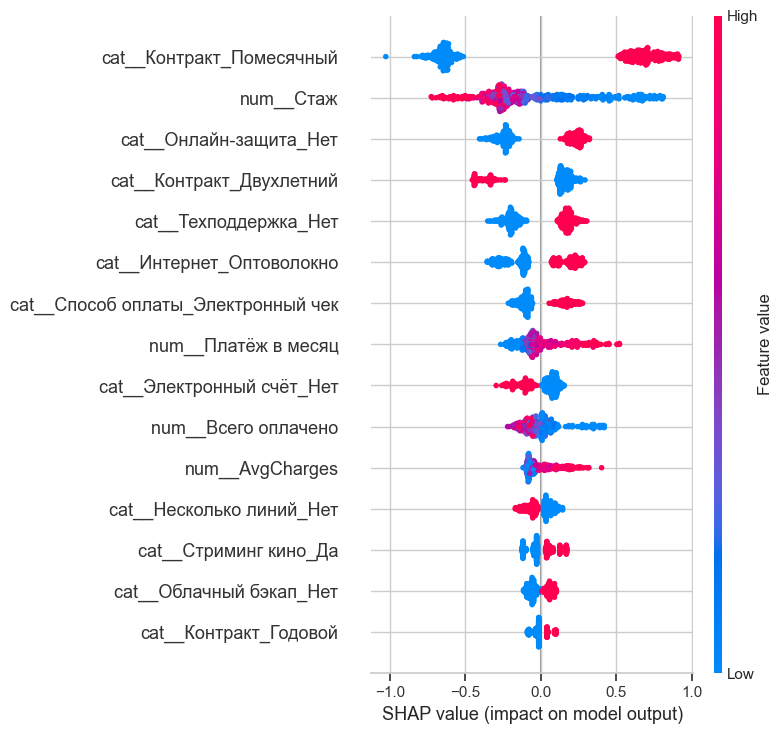

In [18]:
# Для объяснения используем небольшую репрезентативную выборку.
prep = final_model.named_steps["prep"]
model = final_model.named_steps["model"]
X_explain = X_train.sample(n=min(300 if FAST_MODE else 500, len(X_train)), random_state=RANDOM_STATE)
X_trans = prep.transform(X_explain)
feature_names = prep.get_feature_names_out()
try:
    if isinstance(model, (RandomForestClassifier, HistGradientBoostingClassifier)):
        values = shap.TreeExplainer(model).shap_values(X_trans)
        if isinstance(values, list):
            values = values[-1]
        if np.asarray(values).ndim == 3:
            values = np.asarray(values)[:, :, -1]
    elif isinstance(model, LogisticRegression):
        background = prep.transform(X_train.sample(n=min(100, len(X_train)), random_state=RANDOM_STATE))
        values = shap.LinearExplainer(model, background).shap_values(X_trans)
    else:
        raise TypeError("Неизвестный тип модели")
    shap.summary_plot(values, X_trans, feature_names=feature_names, max_display=15, show=True)
except Exception as exc:
    print(f"SHAP пропущен: {type(exc).__name__}: {exc}")
    print("Основная оценка модели и сохранение артефакта от SHAP не зависят.")

**Интерпретация результатов:** ориентируйтесь на таблицу permutation importance и SHAP-график, полученные в текущем запуске. Permutation importance показывает изменение ROC-AUC при перемешивании признака, а не причинный эффект. SHAP описывает вклад признака в выход модели для конкретных наблюдений; направление зависит от шкалы объяснения и способа кодирования.

**Новые признаки:** отдельный ablation study выше сравнивает ROC-AUC с ними и без них на обучающей выборке. Не следует делать вывод об их бесполезности только по близкой к нулю permutation importance. Разница на CV может быть мала относительно разброса по фолдам; для подтверждения улучшения нужен дополнительный независимый эксперимент.

**Ограничение:** permutation importance рассчитана на hold-out test только для объяснения уже зафиксированной модели. Не используйте её для повторного выбора модели или признаков по этому же test.

## 13. Список клиентов в зоне риска
Выгрузка для отдела удержания + сохранение пайплайна целиком.

In [19]:
risk_df = X_test.copy()
risk_df["Скор_оттока"] = y_proba
risk_df["В_зоне_риска"] = y_proba >= best_threshold
print(f"В зоне риска: {risk_df['В_зоне_риска'].sum()} из {len(risk_df)}")
risk_cols = [c for c in [col_tenure, find_col("контракт"), find_col("интернет"),
                         find_col("оплат"), "Скор_оттока"] if c in risk_df.columns]
display(risk_df.sort_values("Скор_оттока", ascending=False).head(20)[risk_cols].round(3))

# Сохраняем только клиентов, для которых модель предсказывает риск ухода.
# Файл содержит клиентские сведения: не публикуйте его в открытом репозитории.
reports_dir = PROJECT_ROOT / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)
risk_csv = reports_dir / "churn_risk_clients.csv"
risk_df.loc[risk_df["В_зоне_риска"]].sort_values(
    "Скор_оттока", ascending=False
).to_csv(risk_csv, index=True, encoding="utf-8-sig")
print(f"CSV клиентов высокого риска: {risk_csv}")

import sklearn
model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)
artifact_path = model_dir / "churn_artifact.pkl"
artifact = {
    "model": final_model,
    "threshold": float(best_threshold),
    "features": X_train.columns.tolist(),
    "sklearn_version": sklearn.__version__,
    "random_state": RANDOM_STATE,
    "fast_mode": FAST_MODE,
}
joblib.dump(artifact, artifact_path, compress=3)
print(f"Модель и порог сохранены: {artifact_path}")
# Проверка сохранения и идентичности предсказаний
loaded = joblib.load(artifact_path)  # загружать только доверенные joblib-файлы
assert np.allclose(loaded["model"].predict_proba(X_test)[:, 1], y_proba)
assert loaded["threshold"] == float(best_threshold)
print("Проверка повторной загрузки: OK")

В зоне риска: 519 из 1409


,Стаж,Контракт,Интернет,Способ оплаты,Скор_оттока
customerID,,,,,
1069-XAIEM,1,Помесячный,Оптоволокно,Электронный чек,0.881
5178-LMXOP,1,Помесячный,Оптоволокно,Электронный чек,0.881
0295-PPHDO,1,Помесячный,Оптоволокно,Электронный чек,0.879
9248-OJYKK,1,Помесячный,Оптоволокно,Электронный чек,0.867
5167-ZFFMM,1,Помесячный,Оптоволокно,Кредитная карта (авто),0.859
2609-IAICY,1,Помесячный,Оптоволокно,Электронный чек,0.859
6861-XWTWQ,7,Помесячный,Оптоволокно,Электронный чек,0.847
9057-SIHCH,3,Помесячный,Оптоволокно,Электронный чек,0.844
8884-ADFVN,7,Помесячный,Оптоволокно,Электронный чек,0.843


CSV клиентов высокого риска: d:\01_Study\Case_02_Telco_Churn\reports\churn_risk_clients.csv
Модель и порог сохранены: d:\01_Study\Case_02_Telco_Churn\models\churn_artifact.pkl
Проверка повторной загрузки: OK


## 14. Итоги и бизнес-рекомендации

Числа ниже рассчитываются при выполнении, а не берутся из предыдущего запуска. OOF-метрики настройки порога и независимые test-метрики показаны отдельно. Рекомендации по скидкам и обзвону — гипотезы для пилотного A/B-теста, а не доказанный экономический эффект.

In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

auc_test = roc_auc_score(y_test, y_proba)
precision_test = precision_score(y_test, y_pred, zero_division=0)
recall_test = recall_score(y_test, y_pred, zero_division=0)
f1_test = f1_score(y_test, y_pred, zero_division=0)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

print(f"""ИТОГИ ПОЛНОГО ЭКСПЕРИМЕНТА
Режим: {'быстрый' if FAST_MODE else 'полный'}
Финальная модель: {best_model_name}
CV ROC-AUC после подбора параметров (возможен оптимизм): {candidate_scores[best_model_name]:.4f}

НАСТРОЙКА ПОРОГА (OOF НА TRAIN, НЕ TEST):
Порог: {best_threshold:.4f}
OOF Recall: {best_recall:.2%}
OOF Precision: {best_precision:.2%}

НЕЗАВИСИМАЯ ОЦЕНКА НА TEST:
ROC-AUC: {auc_test:.4f}
Precision: {precision_test:.2%}
Recall: {recall_test:.2%}
F1-score: {f1_test:.4f}
Матрица ошибок: TN={tn}, FP={fp}, FN={fn}, TP={tp}
В зоне риска: {int(risk_df['В_зоне_риска'].sum())} из {len(risk_df)}

ТОП-5 признаков (permutation importance, ассоциации, не причинные эффекты):
{importance.tail(5)[::-1].to_string()}

БИЗНЕС-ГИПОТЕЗЫ ДЛЯ ПРОВЕРКИ:
Онбординг новых клиентов; предложения по более длительным контрактам;
приоритизация контактов с клиентами высокого риска.
Экономический эффект и эффективность скидок следует проверить в A/B-тесте.""")
print("\nABLATION (train CV, не test):")
print(ablation_report.round(4).to_string(index=False))
print("CSV высокого риска:", risk_csv)


ИТОГИ ПОЛНОГО ЭКСПЕРИМЕНТА
Режим: полный
Финальная модель: HistGB + Optuna
CV ROC-AUC после подбора параметров (возможен оптимизм): 0.8497

НАСТРОЙКА ПОРОГА (OOF НА TRAIN, НЕ TEST):
Порог: 0.3126
OOF Recall: 75.05%
OOF Precision: 55.38%

НЕЗАВИСИМАЯ ОЦЕНКА НА TEST:
ROC-AUC: 0.8487
Precision: 54.34%
Recall: 75.40%
F1-score: 0.6316
Матрица ошибок: TN=798, FP=237, FN=92, TP=282
В зоне риска: 519 из 1409

ТОП-5 признаков (permutation importance, ассоциации, не причинные эффекты):
Контракт          0.101113
Стаж              0.040983
Интернет          0.008905
Онлайн-защита     0.007331
Всего оплачено    0.006608

БИЗНЕС-ГИПОТЕЗЫ ДЛЯ ПРОВЕРКИ:
Онбординг новых клиентов; предложения по более длительным контрактам;
приоритизация контактов с клиентами высокого риска.
Экономический эффект и эффективность скидок следует проверить в A/B-тесте.

ABLATION (train CV, не test):
           Вариант  ROC-AUC CV (среднее)  ROC-AUC CV (std)
 С дополнительными                0.8497            0.0109
Без доп

In [21]:
# Итоговые автоматические проверки после полного запуска
assert X_train.index.intersection(X_test.index).empty
assert set(np.unique(y_pred)).issubset({0, 1})
assert np.isfinite(y_proba).all()
assert 0 <= best_threshold <= 1
assert artifact_path.exists()
assert len(y_proba) == len(y_test)
print("ВСЕ БАЗОВЫЕ ПРОВЕРКИ ПРОЙДЕНЫ")
print("Режим:", "быстрый" if FAST_MODE else "полный")
print("ROC-AUC test:", round(roc_auc_score(y_test, y_proba), 4))
assert abs(precision_test - precision_score(y_test, y_pred, zero_division=0)) < 1e-12
assert abs(recall_test - recall_score(y_test, y_pred, zero_division=0)) < 1e-12
assert loaded["features"] == X_train.columns.tolist()
assert loaded["fast_mode"] == FAST_MODE
print("Артефакт, порог и схема признаков: OK")

ВСЕ БАЗОВЫЕ ПРОВЕРКИ ПРОЙДЕНЫ
Режим: полный
ROC-AUC test: 0.8487
Артефакт, порог и схема признаков: OK
